# Notebook 05: Scenario 2 - Synthetic Dataset Analysis
**Project:** Real vs. Synthetic Data: Comparative Analysis and Visualization
**Data analysed:** the synthetic data (`data/synthetic/synthetic_online_shoppers.csv`, 12,199 sessions, Gaussian Copula, seed 42)

This repeats the identical analysis of notebook 04 on the synthetic data. Every function, variable, bin edge, axis limit and sample (seed 42) is shared through `src/scenario_lib.py`, so the two notebooks can be compared directly. The analysis covers univariate, bivariate and multivariate views and a monthly trend, and ends with five key findings. Each figure is followed by a short interpretation.

**Fair-comparison settings.** The x-axis limit of a numerical column is the *real* 99th percentile in all scenarios; the y-axis limits are the larger of the real and synthetic values, so neither scenario is clipped. Counts and shares are shown as a percentage of each dataset's rows.

**Where the work is done.** Charts that Power BI can draw natively (histograms, bars, scatter, line, donut) are repeated in Power BI in a later phase. Charts it cannot draw (KDE, pair plot, heatmaps) are produced here.

## 1. Setup

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
warnings.filterwarnings("ignore")

ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import scenario_lib as L
L.use_style()

real = pd.read_csv(ROOT / "data" / "cleaned" / "online_shoppers_cleaned.csv")
syn = pd.read_csv(ROOT / "data" / "synthetic" / "synthetic_online_shoppers.csv")
S = L.make_settings(real, syn)                 # identical for every scenario
LIM = L.trend_limits(real, syn)
df = syn
COLOR = L.SCENARIO_COLOR["Synthetic"]
FIG = ROOT / "figures" / "synthetic/scenario2"
RES = ROOT / "results" / "scenarios" / "scenario2_synthetic"
RES.mkdir(parents=True, exist_ok=True)
r2 = lambda d: {k: round(float(v), 4) for k, v in d.items()}
json.dump({"x_axis_limit (real p99)": r2(S["hi"]), "histogram_y_max (% of rows)": r2(S["hist_ymax"]), "kde_y_max": r2(S["kde_ymax"]),
           "category_y_max (% of rows)": r2(S["cat_ymax"]), "purchase_rate_axis_max": S["rate_ymax"], "grouped_bar_axis_max": S["bar_ymax"],
           "bubble_x_max": S["bubble_xmax"], "random_seed_for_samples": L.SEED}, open(ROOT / "results" / "scenarios" / "plot_settings.json", "w"), indent=1)
print("Scenario 2 data:", df.shape, "| numerical:", len(L.NUM), "| categorical:", len(L.CAT))
print("Missing values:", int(df.isna().sum().sum()), "| Revenue:", df.Revenue.value_counts().to_dict())

Scenario 2 data: (12199, 24) | numerical: 14 | categorical: 10
Missing values: 0 | Revenue: {'No_Purchase': 10468, 'Purchase': 1731}


## 2. Univariate analysis

### 2.1 Numerical columns: mean, median, mode, standard deviation, quartiles, skewness and outliers
Outliers are counted with the 1.5 x IQR rule on this scenario's own data. `above axis limit` is the share of values beyond the real 99th percentile used as the plot limit.

In [2]:
num_stats = L.univariate_numeric(df, S)
num_stats.to_csv(RES / "univariate_numeric.csv")
num_stats.round(3)

,mean,median,mode,std,min,Q1,Q3,max,skewness,IQR outliers (n),IQR outliers (%),zeros (%),above axis limit (%)
column,,,,,,,,,,,,,
Administrative,2.156,2.000,0.0,2.601,0.0,0.000,4.000,27.000,1.656,152,1.246,43.233,0.205
Administrative_Duration,61.279,18.671,0.0,107.446,0.0,0.000,84.573,1178.967,4.021,809,6.632,47.783,0.262
Informational,0.643,0.000,0.0,1.007,0.0,0.000,2.000,6.000,1.225,1,0.008,67.743,0.000
Informational_Duration,22.264,0.000,0.0,47.692,0.0,0.000,21.945,501.570,2.901,2106,17.264,74.301,0.000
ProductRelated,32.934,17.000,4.0,46.027,1.0,7.000,38.000,282.000,3.102,1091,8.943,0.000,1.631
ProductRelated_Duration,1260.716,534.021,0.0,1983.100,0.0,205.128,1361.805,11246.177,3.116,1232,10.099,2.722,2.115
BounceRates,0.014,0.004,0.0,0.025,0.0,0.000,0.017,0.200,3.571,1006,8.247,44.545,0.000
ExitRates,0.040,0.025,0.2,0.041,0.0,0.013,0.050,0.200,2.119,920,7.542,0.000,0.000
PageValues,5.746,0.000,0.0,10.209,0.0,0.000,10.087,125.004,2.369,711,5.828,67.145,0.033


**Interpretation (compared with Scenario 1).** The synthetic data has the same overall character: zero-inflated, right-skewed columns, with means close to the real ones for the main browsing columns (ProductRelated 32.9 against 31.6, Total_Pages 35.7 against 34.4, Total_Duration 1,344 s against 1,295 s, PageValues 5.75 against 5.95). The differences are in spread and shape. Standard deviations are lower for the sparse columns (PageValues 10.2 against 18.7; Informational_Duration 47.7 against 120.2) and skewness is much lower (PageValues 2.4 against 6.4; Informational 1.2 against 4.0; Informational_Duration 2.9 against 5.5; Avg_Time_Per_Page 3.3 against 10.3, where the real value is driven by one session of 1,364 s per page against a synthetic maximum of 606 s). The synthetic data has fewer exact zeros in the sparse columns (PageValues 67% against 78%, Informational 68% against 78%), so their third quartile is no longer 0 (10.1 and 2.0), and it has no zero ProductRelated at all (real 0.26%). The IQR rule flags only 5.8% of PageValues and 0.01% of Informational values, against 22.4% and 21.6% in the real data; this does not mean the synthetic data is cleaner, it only reflects the changed quartiles. About twice as many synthetic values lie above the real 99th percentile for the product and total columns (1.5% to 2.1%), while PageValues, Informational and Informational_Duration have almost none. The most common value of ProductRelated is 4 (real 1) and of Total_Pages 7 (real 1): single-page sessions are less frequent in the synthetic data.

### 2.2 Categorical columns: frequency and percentage

In [3]:
cat_freq = L.categorical_freq(df)
cat_freq.to_csv(RES / "categorical_frequency.csv", index=False)
top = cat_freq.sort_values(["column", "count"], ascending=[True, False]).groupby("column").head(3)
top.round(2).reset_index(drop=True)      # the three most frequent levels of each column (the full table is in the CSV)

,column,level,count,percent
0,Browser,Browser_2,7944,65.12
1,Browser,Browser_1,2417,19.81
2,Browser,Browser_4,688,5.64
3,Month,May,3392,27.81
4,Month,Nov,3017,24.73
5,Month,Mar,1783,14.62
6,OperatingSystems,OS_2,6713,55.03
7,OperatingSystems,OS_1,2469,20.24
8,OperatingSystems,OS_3,2439,19.99
9,Quarter,Q4,5230,42.87


**Interpretation (compared with Scenario 1).** The category shares are very close to the real ones, within about 1.5 percentage points for the levels listed: May 27.8% (real 27.3%), November 24.7% (24.4%), Q4 42.9% (42.9%), returning visitors 86.2% (85.5%), new visitors 13.2% (13.9%), weekday 77.7% (76.6%), OS_2 55.0% (53.6%), Browser_2 65.1% (64.6%), Region_1 38.5% (38.6%) and Traffic_2 32.9% (32.1%). The one visible gap is the purchase rate: 14.19% (95% interval 13.6% to 14.8%) against 15.64% in the real data, so the real rate lies outside the interval of the synthetic rate.

### 2.3 Histograms

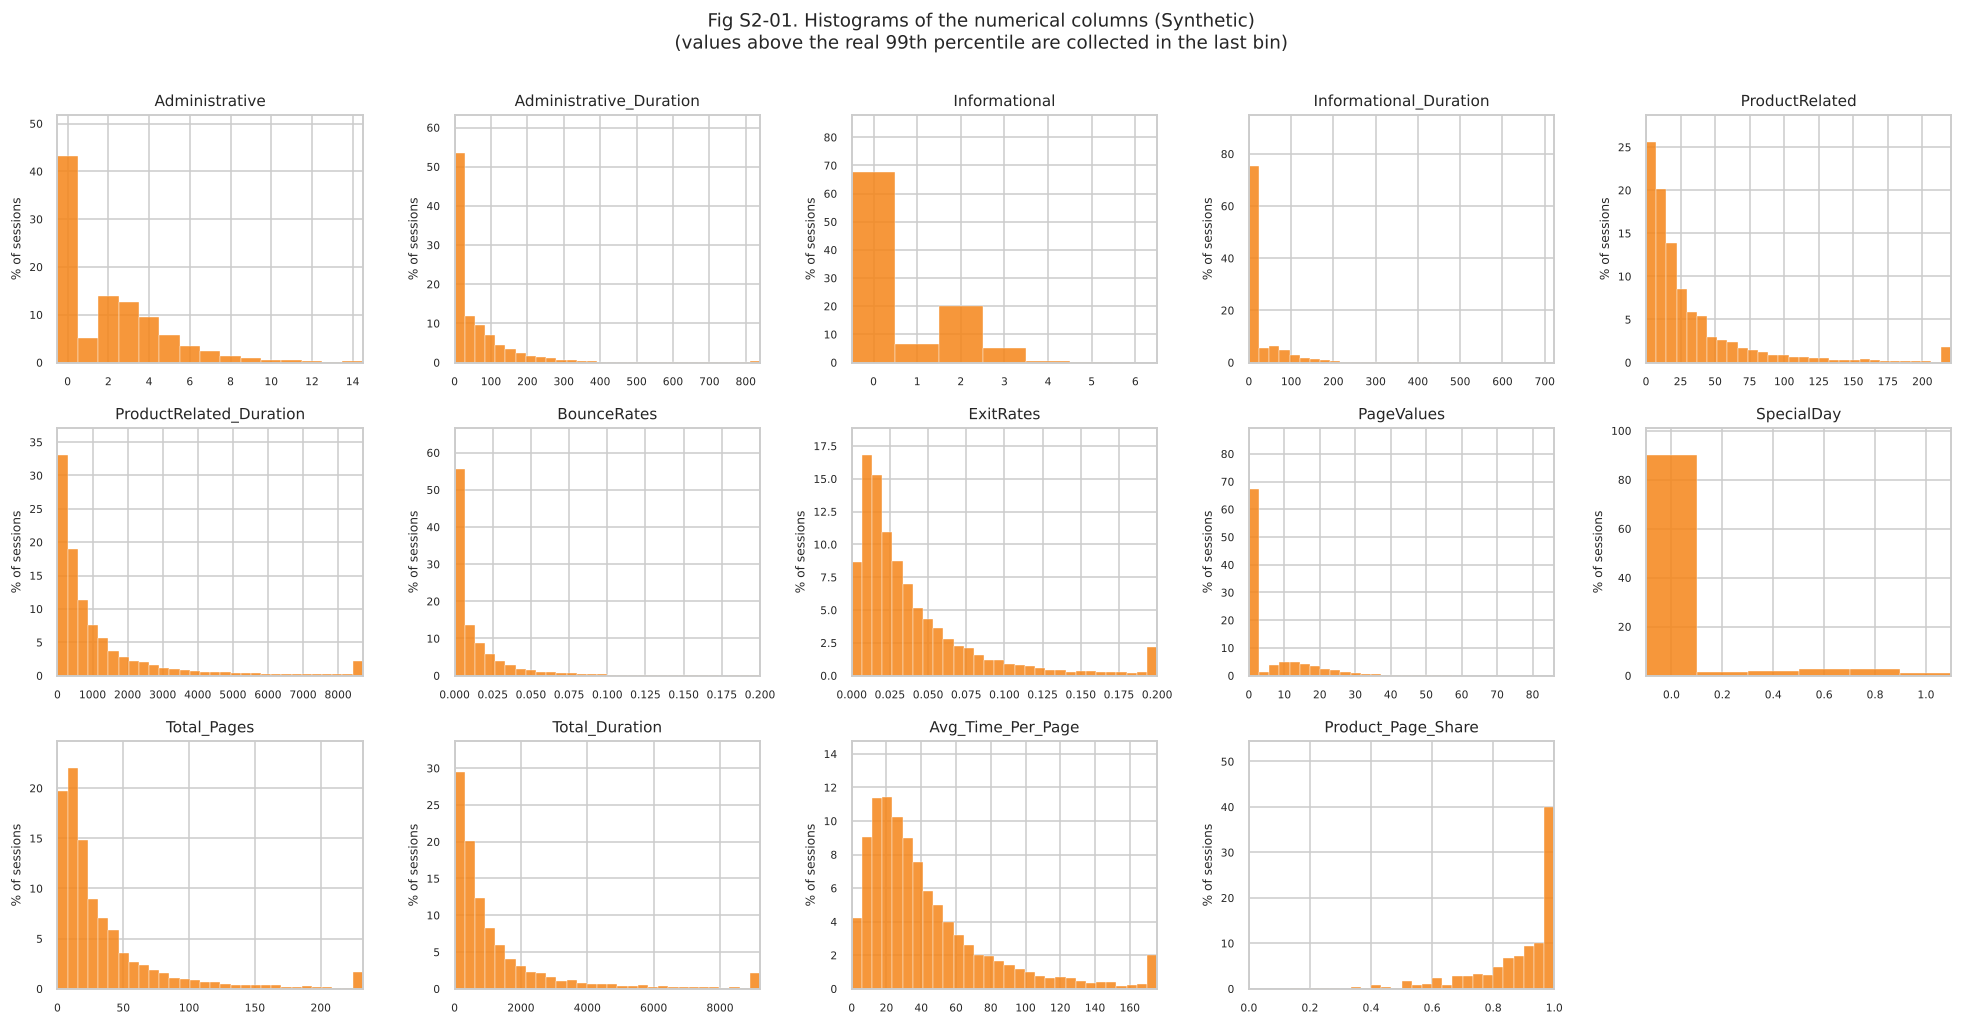

In [4]:
L.fig_histograms(df, S, COLOR, "Fig S2-01. Histograms of the numerical columns (Synthetic)", FIG / "s2_01_histograms.png")

**Interpretation (compared with Scenario 1).** The histograms of ProductRelated, the durations, Total_Pages and Total_Duration have the same decaying shape as in Scenario 1. Differences: Administrative has a deficit at 1 page (5.0% against 11.1%) and bumps at 2 to 4 pages (13.9%, 12.7%, 9.5% against 9.1%, 7.5%, 6.3%); Informational has an excess at exactly 2 pages (20.1% against 6.0%) and no values above 6 (real maximum 24); the spike of BounceRates at the cap of 0.2 almost disappears (0.2% of sessions against 4.7%); and PageValues has a bump around 10 to 20 with fewer zeros (67% against 78%). These come from modelling the non-zero values as a smooth distribution and rounding the counts.

### 2.4 KDE plots

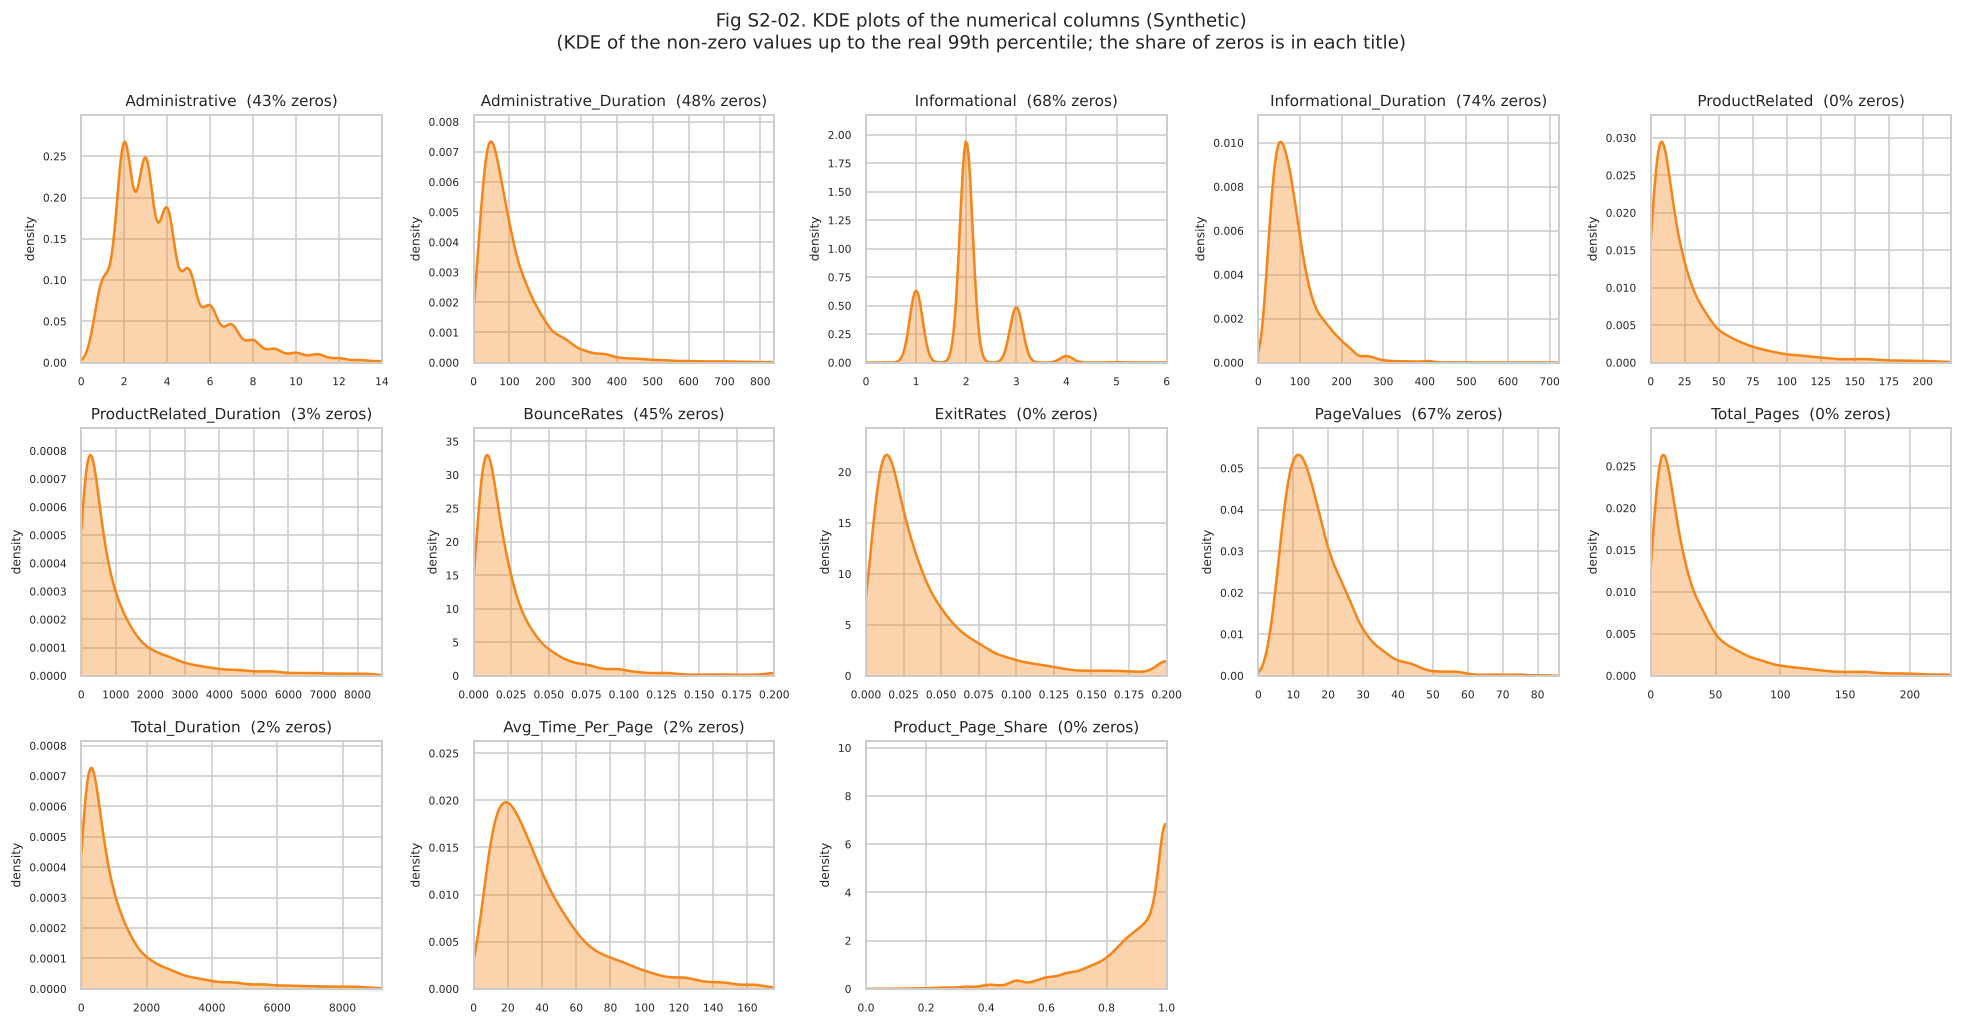

In [5]:
L.fig_kde(df, S, COLOR, "Fig S2-02. KDE plots of the numerical columns (Synthetic)", FIG / "s2_02_kde.png")

**Interpretation (compared with Scenario 1).** The non-zero values of the duration and count columns again form one skewed hump, with a similar location. The hump for PageValues is narrower: the 10th to 90th percentile of the non-zero values is 7.4 to 30.4 against 3.2 to 60.4 in the real data, so the real data has more very small and very large values. Informational is dominated by a peak at 2 and ExitRates has a smaller bump at the cap of 0.2 (2.0% of sessions at 0.2 against 4.8%).

### 2.5 Box plots

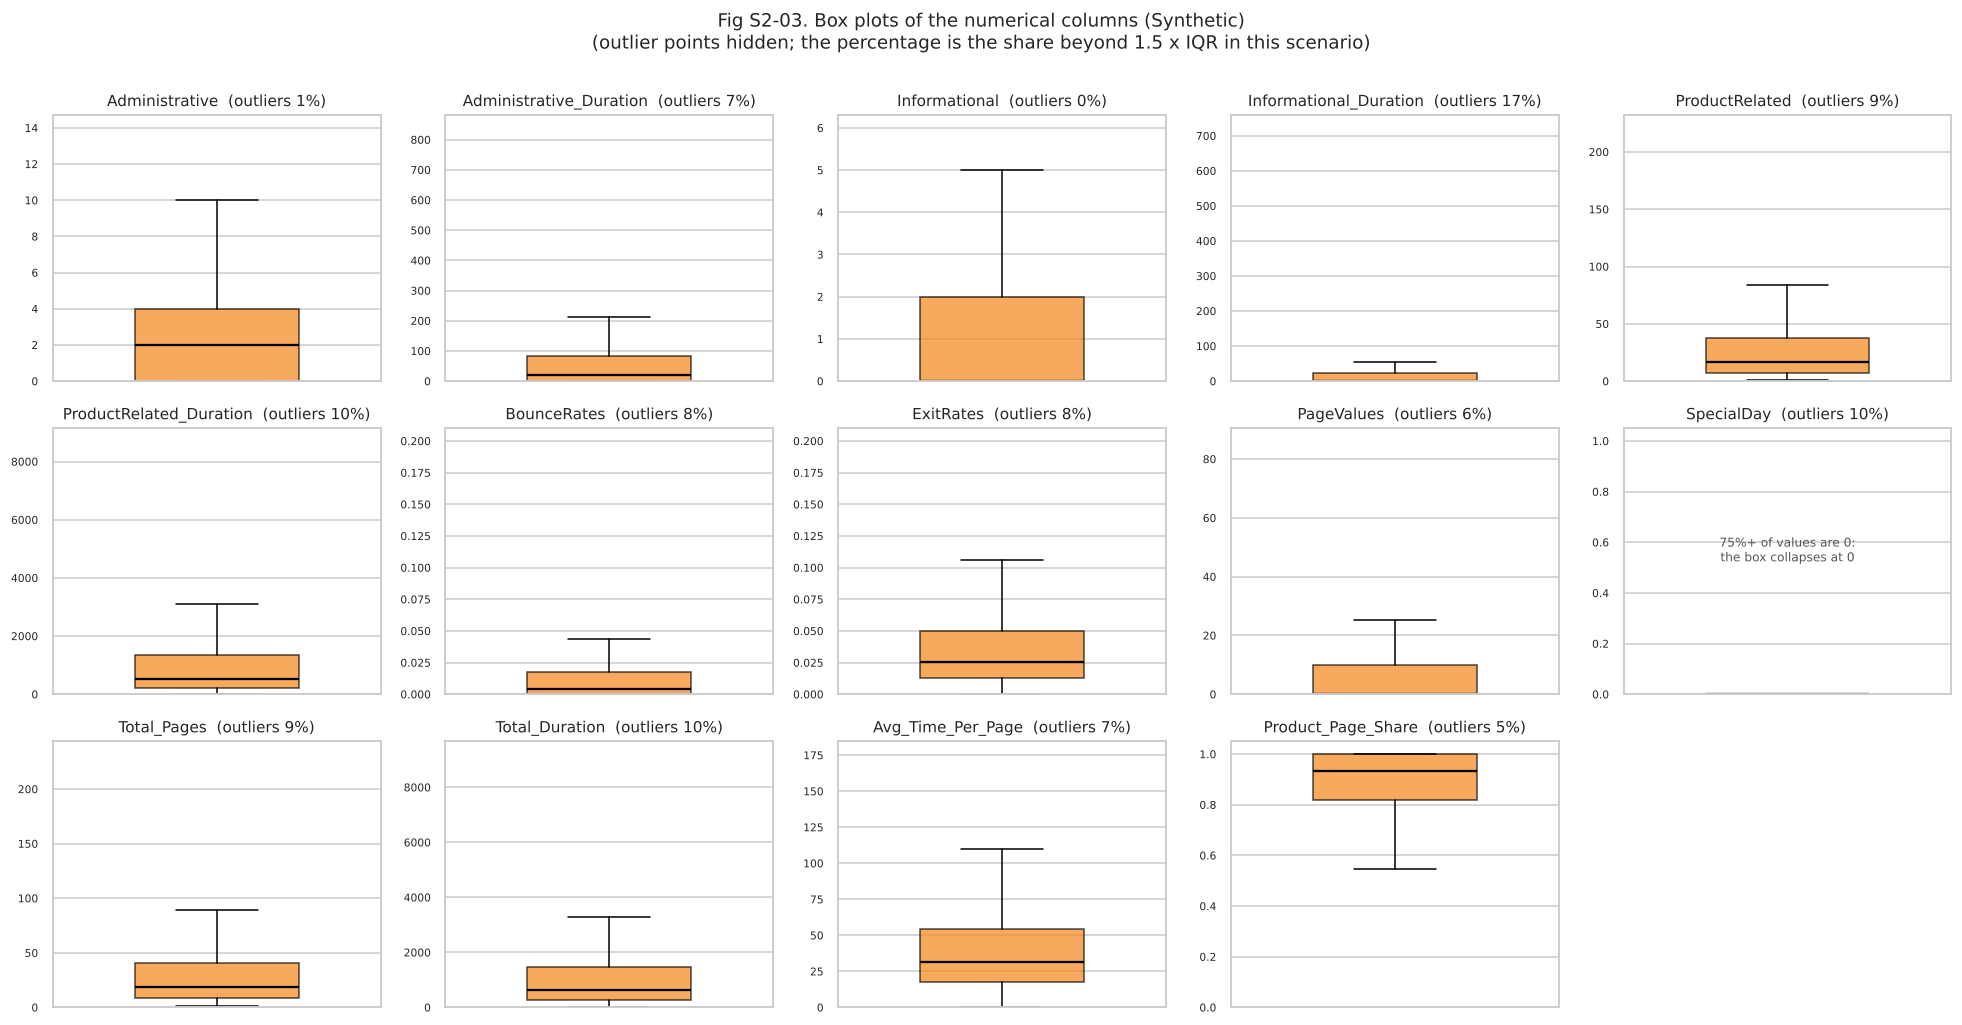

In [6]:
L.fig_boxplots(df, S, COLOR, "Fig S2-03. Box plots of the numerical columns (Synthetic)", FIG / "s2_03_boxplots.png")

**Interpretation (compared with Scenario 1).** The boxes and whiskers of the count and duration columns are close to Scenario 1 (for example the ProductRelated quartiles are 7 and 38 against 8 and 38). Two differences stand out. PageValues and Informational no longer have a collapsed box, because less than 75% of their values are 0 (third quartiles of 10.1 and 2, against 0 in the real data); and the outlier percentages of these columns are very different (5.8% and 0.01% against 22.4% and 21.6%) for the reason given in Section 2.1.

### 2.6 Bar charts of the categorical columns

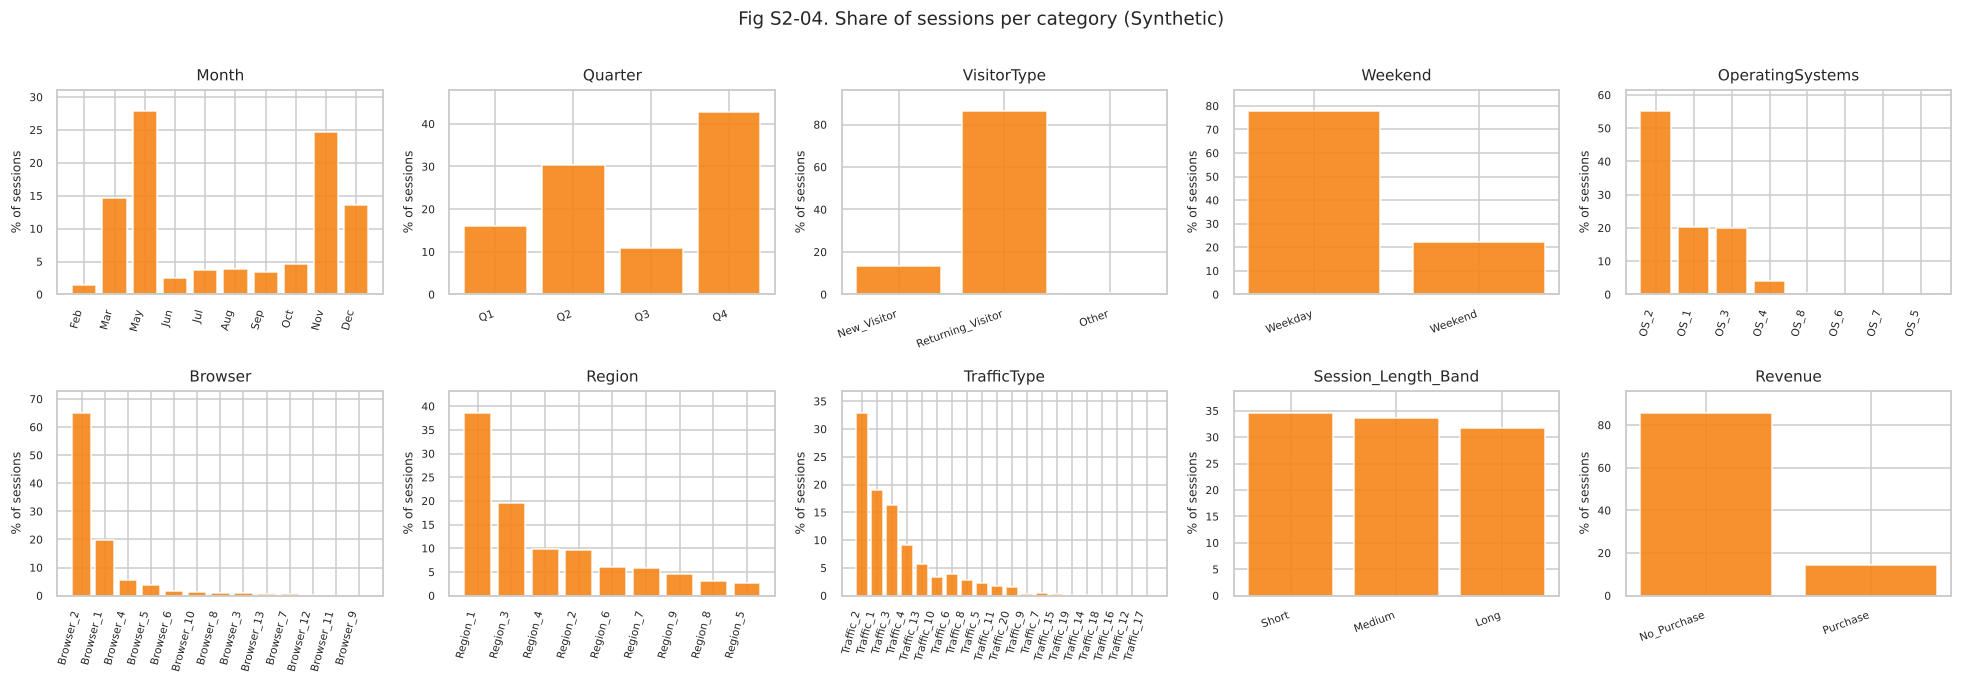

In [7]:
L.fig_categorical_bars(df, S, COLOR, "Fig S2-04. Share of sessions per category (Synthetic)", FIG / "s2_04_categorical_bars.png")

**Interpretation (compared with Scenario 1).** The bars are almost the same height as in Scenario 1 for every categorical column, including the rare levels, so the one-way category distributions are reproduced very well. This says nothing about whether the categories occur in the right combinations with each other, which is tested in the bivariate and multivariate sections.

### 2.7 Donut charts

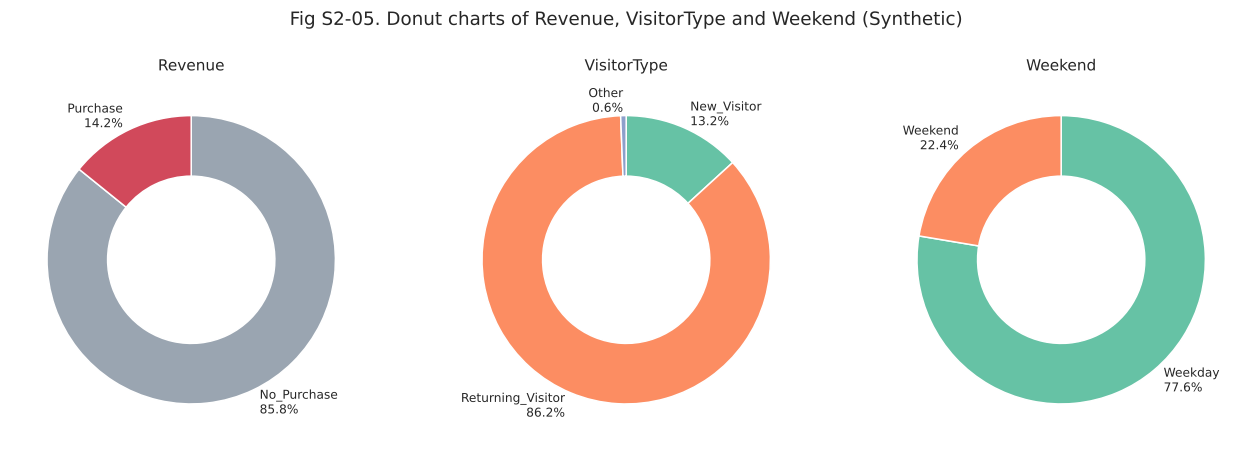

In [8]:
L.fig_donuts(df, S, "Fig S2-05. Donut charts of Revenue, VisitorType and Weekend (Synthetic)", FIG / "s2_05_donuts.png")

**Interpretation (compared with Scenario 1).** The donuts look almost the same as in Scenario 1: 14.2% of sessions end in a purchase (real 15.6%), 86.2% of sessions are returning visitors and 77.7% happen on weekdays. The small difference in the purchase share is the only visible change.

## 3. Bivariate analysis
Four numerical pairs (scatter plots), four numerical-by-category comparisons (box plots), three purchase-rate comparisons (grouped bar charts) and the correlation heatmaps. The tests below give the statistical evidence for each pair.

In [9]:
tests = L.bivariate_tests(df)
tests.to_csv(RES / "bivariate_tests.csv", index=False)
tests.assign(**{"p-value": tests["p-value"].map(lambda p: "<0.0001" if p < 1e-4 else f"{p:.4f}")}).round({"effect": 3})

,test,pair,statistic,effect,p-value
0,correlation,ProductRelated ~ ProductRelated_Duration,Pearson r = 0.666; Spearman rho = 0.743,0.743,<0.0001
1,correlation,BounceRates ~ ExitRates,Pearson r = 0.519; Spearman rho = 0.447,0.447,<0.0001
2,correlation,ExitRates ~ PageValues,Pearson r = -0.149; Spearman rho = -0.206,-0.206,<0.0001
3,correlation,Total_Pages ~ PageValues,Pearson r = 0.142; Spearman rho = 0.259,0.259,<0.0001
4,Mann-Whitney U,PageValues by Revenue,"median purchase = 8.54, no purchase = 0",0.302,<0.0001
5,Mann-Whitney U,ExitRates by Revenue,"median purchase = 0.0197, no purchase = 0.0266",-0.175,<0.0001
6,Mann-Whitney U,Total_Pages by Revenue,"median purchase = 25, no purchase = 19",0.141,<0.0001
7,Mann-Whitney U,Total_Duration by Revenue,"median purchase = 865, no purchase = 589",0.151,<0.0001
8,chi-square,VisitorType x Revenue,"chi2 = 15.5, dof = 2",0.036,0.0004
9,chi-square,Quarter x Revenue,"chi2 = 18.6, dof = 3",0.039,0.0003


**Interpretation (compared with Scenario 1).** The direction of every relationship is kept, but the strength is reduced. Correlations: product pages with product time 0.74 against 0.88 (Spearman); BounceRates with ExitRates 0.52 against 0.90 (Pearson) and 0.45 against 0.59 (Spearman); ExitRates with PageValues -0.21 against -0.30; Total_Pages with PageValues 0.26 against 0.35. Purchase against no purchase: the rank-biserial effect of PageValues falls from 0.73 to 0.30, of ExitRates from -0.40 to -0.17, of Total_Pages from 0.32 to 0.14 and of Total_Duration from 0.34 to 0.15. Association of categorical variables with purchase (Cramér's V): session length 0.078 against 0.185, month 0.053 against 0.176, quarter 0.039 against 0.137, visitor type 0.036 against 0.103. The weekend effect, which is small but significant in the real data (V = 0.027, p = 0.0024), is not present in the synthetic data (V = 0.004, p = 0.69).

### 3.1 Scatter plots (four pairs)

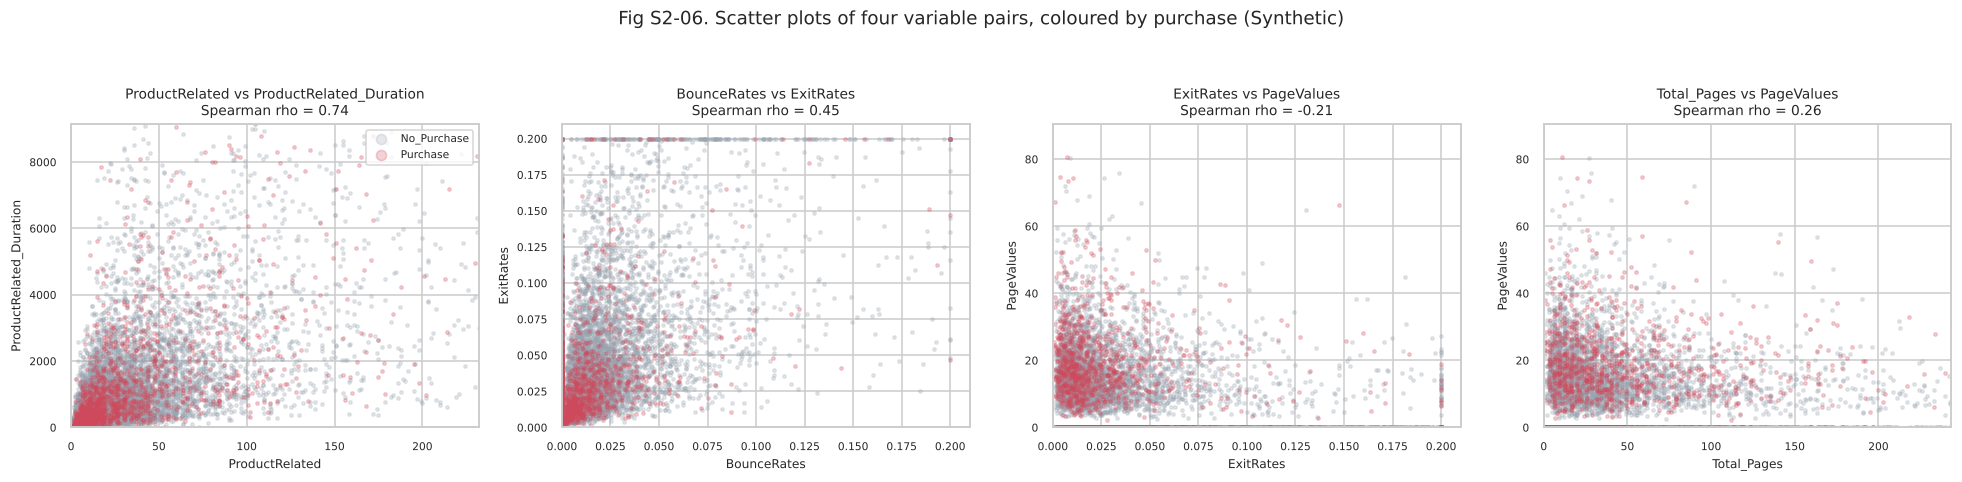

In [10]:
L.fig_scatter_pairs(df, S, "Fig S2-06. Scatter plots of four variable pairs, coloured by purchase (Synthetic)", FIG / "s2_06_scatter_pairs.png")

**Interpretation (compared with Scenario 1).** The product-page band is still visible but looser (rho 0.74 against 0.88), and the cluster of sessions at bounce and exit rate 0.2 is much smaller than in the real data. The two PageValues panels show the same direction (negative against ExitRates, positive against Total_Pages) but with weaker rank correlations (-0.21 and 0.26). Purchasing sessions (red) are spread over a wider range of PageValues instead of concentrating at the top, as they do in Scenario 1.

### 3.2 Box plots across categories

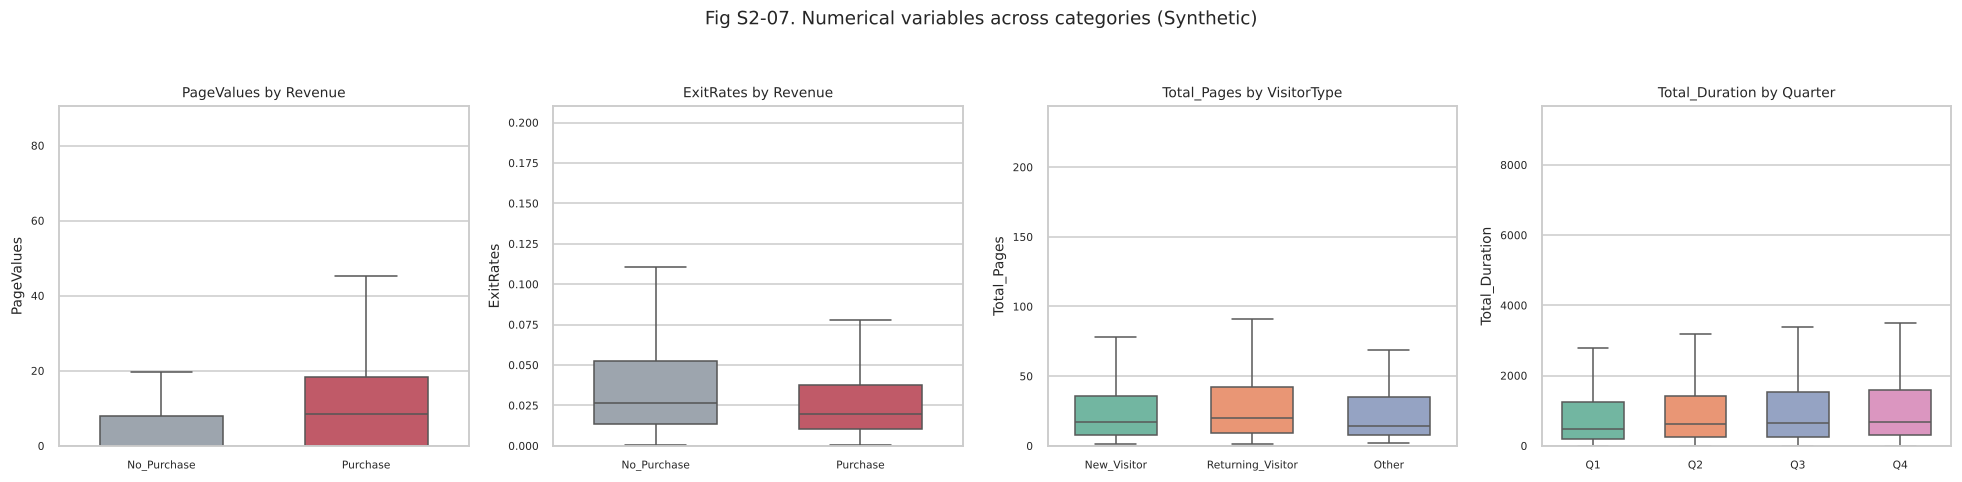

In [11]:
L.fig_box_by_category(df, S, "Fig S2-07. Numerical variables across categories (Synthetic)", FIG / "s2_07_box_by_category.png")

**Interpretation (compared with Scenario 1).** The purchasing sessions still have higher PageValues, but the median is 8.5 against 16.8 in the real data. ExitRates is lower for purchasing sessions (median 0.020 against 0.027), but the gap is smaller than in Scenario 1 (0.016 against 0.028). Returning visitors view slightly more pages (median 20 against 17 for new visitors; real 22 against 16), and the median total time rises from 476 s in Q1 to 683 s in Q4 (real 497 s to 870 s), so the ordering by quarter is kept with a smaller increase.

### 3.3 Grouped bar charts: purchase rate

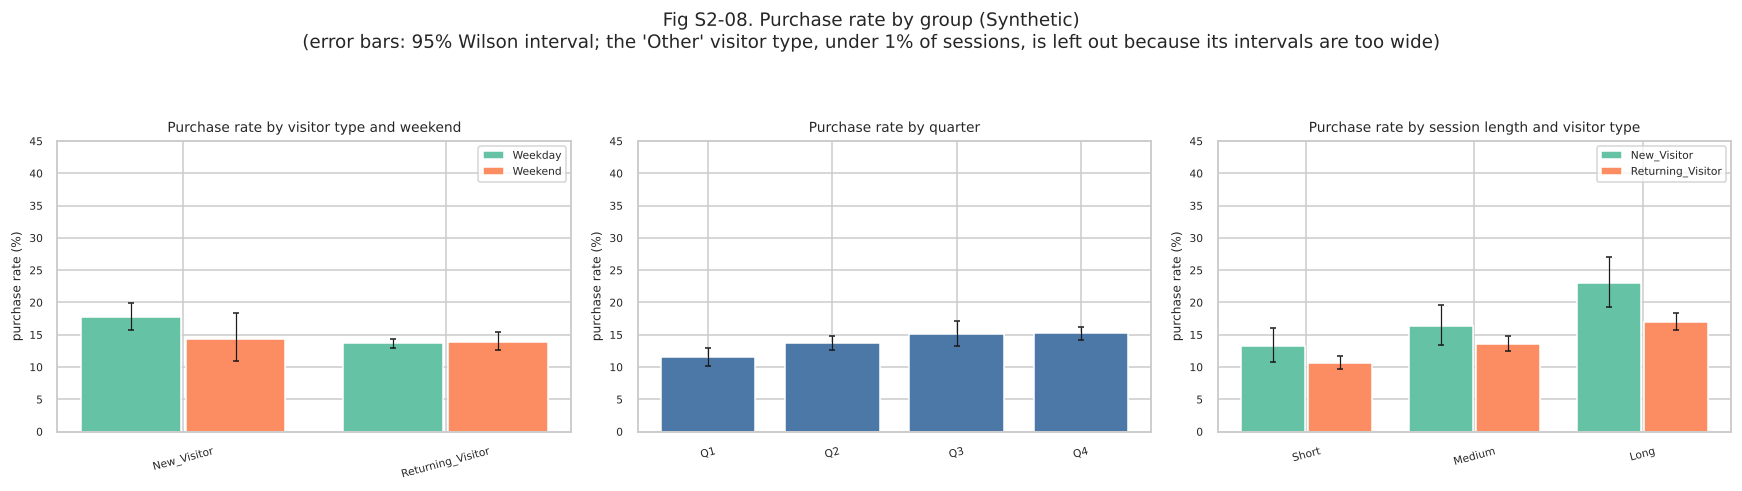

In [12]:
L.fig_purchase_rate_bars(df, S, "Fig S2-08. Purchase rate by group (Synthetic)", FIG / "s2_08_purchase_rate_bars.png")

**Interpretation (compared with Scenario 1).** The ordering of the groups is mostly kept but the differences are compressed. New visitors buy at 17.0% against 13.7% for returning visitors (real 24.9% against 14.1%). The purchase rate rises from 11.5% in Q1 to 15.3% in Q4 (real 9.6% to 20.8%), and from 11.1% for short to 17.8% for long sessions (real 7.0% to 23.2%). Many of the intervals now overlap, which they do not in the real data (for example the intervals of Q3 and Q4 are 13.3% to 17.2% and 14.3% to 16.3%).

### 3.4 Correlation heatmaps

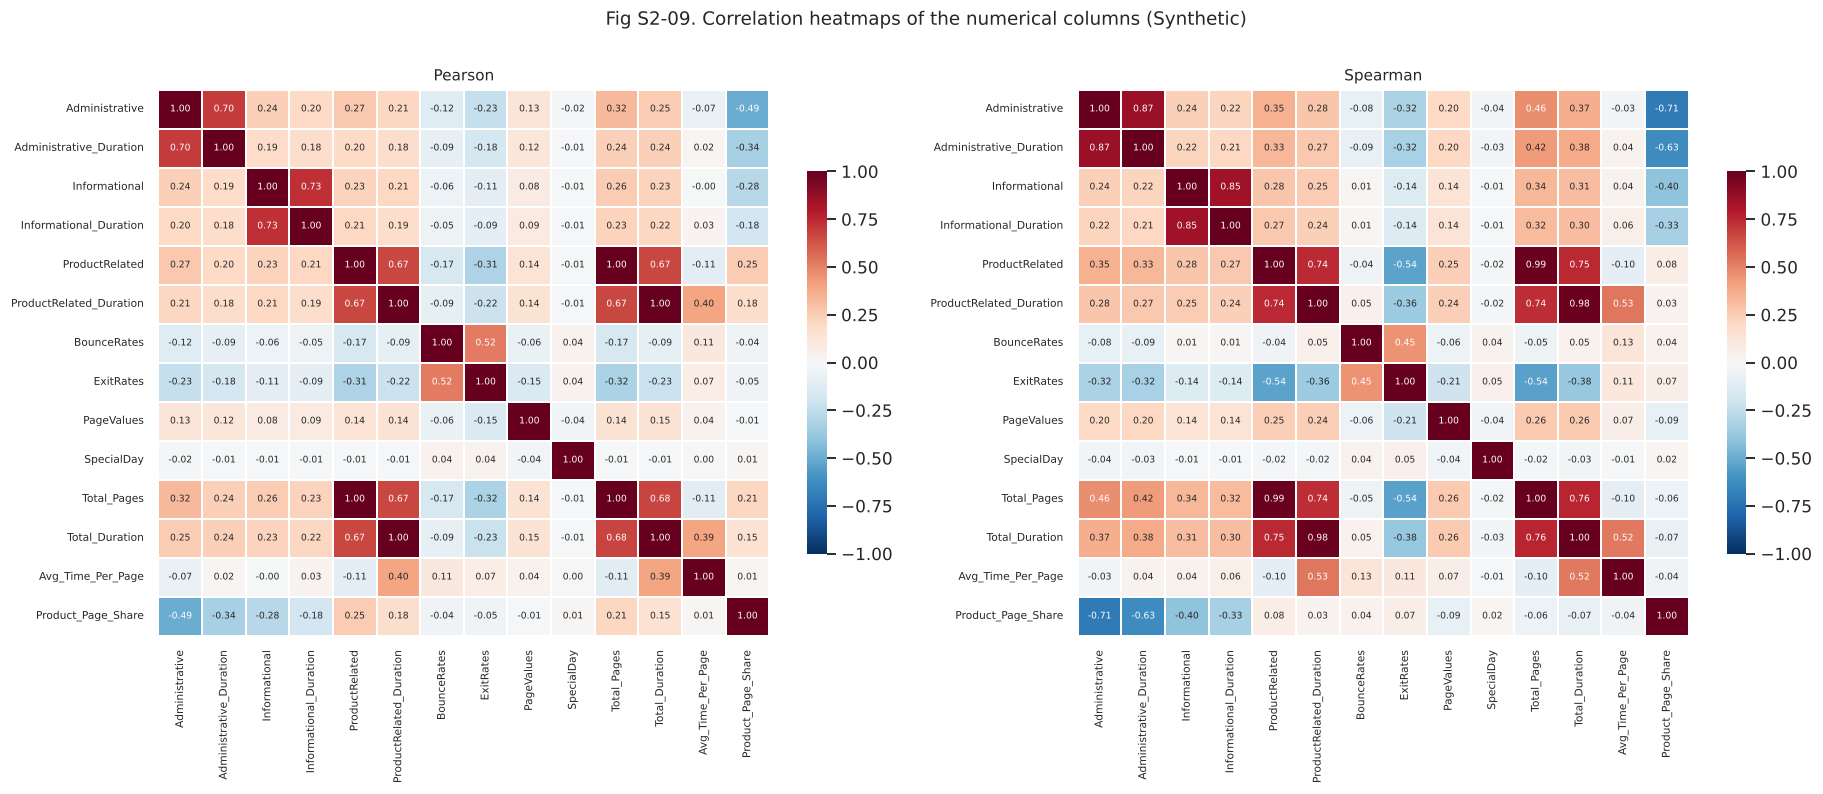

In [13]:
L.fig_correlation_heatmaps(df, "Fig S2-09. Correlation heatmaps of the numerical columns (Synthetic)", FIG / "s2_09_correlation_heatmaps.png")
df[L.NUM].corr().to_csv(RES / "correlation_pearson.csv"); df[L.NUM].corr(method="spearman").to_csv(RES / "correlation_spearman.csv")

**Interpretation (compared with Scenario 1).** The pattern of the correlation matrix is similar, with the same mechanical relations (Total_Pages and ProductRelated 1.00, Total_Duration and ProductRelated_Duration 0.99) and the same sign for most pairs. The main differences: ProductRelated with its duration is 0.67 (real 0.87), BounceRates with ExitRates 0.52 (real 0.90), and the sign of BounceRates with Avg_Time_Per_Page flips (Pearson +0.11 against -0.17). Avg_Time_Per_Page is more strongly related to ProductRelated_Duration (0.40 against 0.22). Some pairs are as strong or stronger than in the real data: Administrative with its duration 0.70 (real 0.65) and Informational with its duration 0.73 (real 0.66). The relation of Product_Page_Share with Administrative (-0.49) is exactly kept.

## 4. Multivariate analysis
Three patterns are examined: (1) the relation between value, exit behaviour, size of the visit and time per page for buying and non-buying sessions; (2) month x visitor-type groups (activity against purchase rate); (3) PageValues against ExitRates within each visitor type, plus the purchase rate by quarter and visitor type.

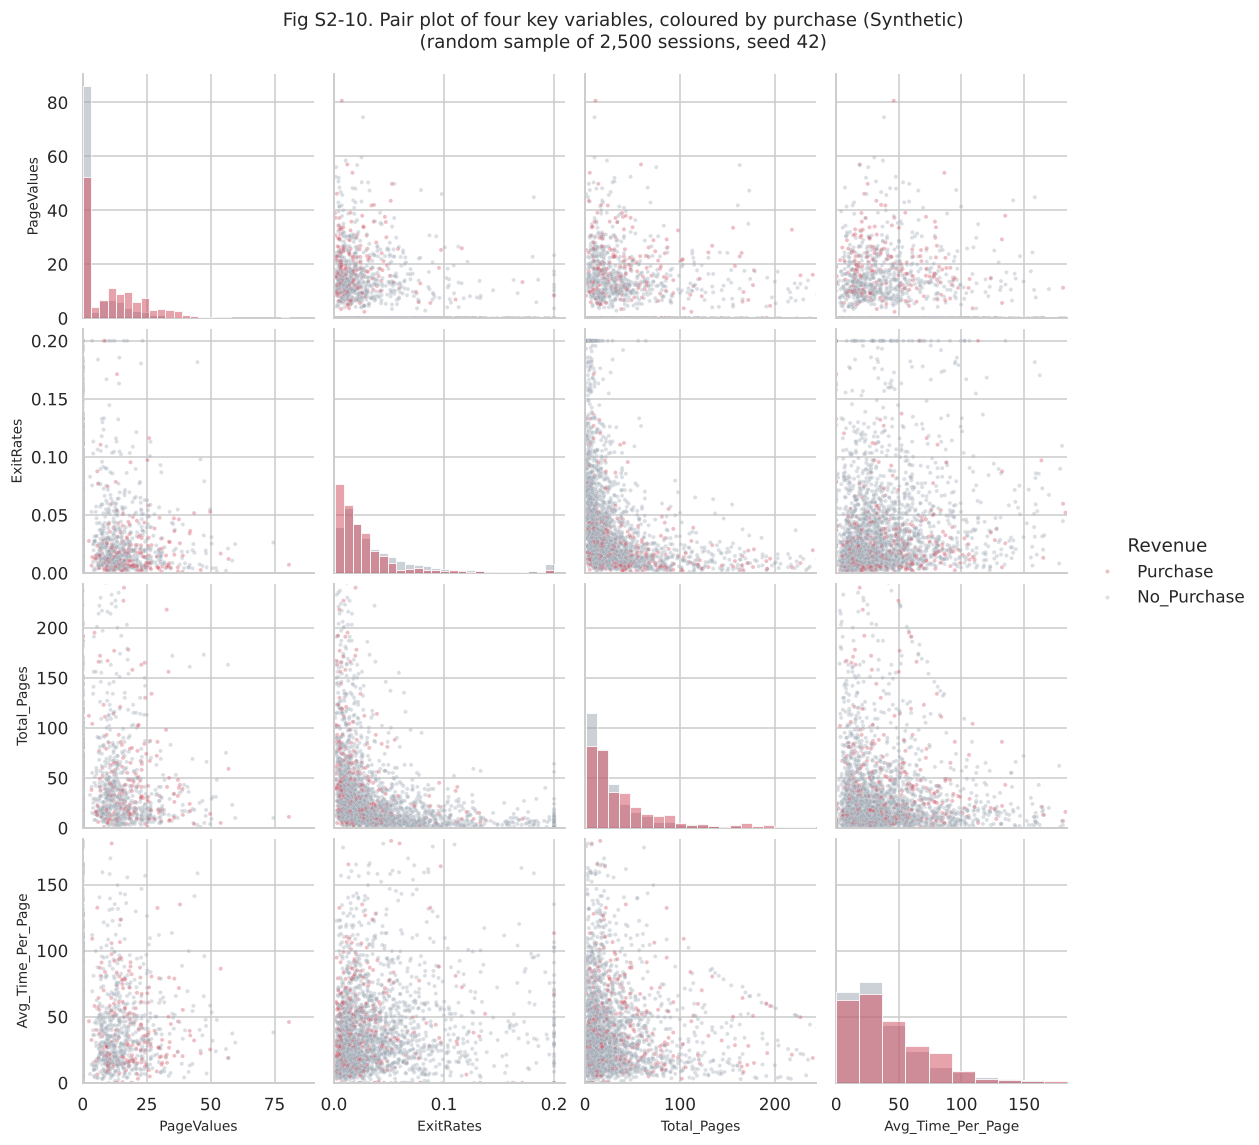

In [14]:
L.fig_pairplot(df, S, "Fig S2-10. Pair plot of four key variables, coloured by purchase (Synthetic)", FIG / "s2_10_pairplot.png")

**Interpretation (compared with Scenario 1).** The synthetic pair plot has the same layout, but the purchase signal in PageValues is much weaker. Only 153 synthetic sessions have PageValues above 40 (578 in the real data), and of these 33% are purchases (real 80%); above 20 the purchase share is 30% (real 73%). Purchases among sessions with an exit rate above 0.1 are no longer rare: 7.8% of the 1,020 such sessions end in a purchase (real 0.6% of 981). The synthetic generator therefore produces PageValues and ExitRates values that are less informative about purchase.

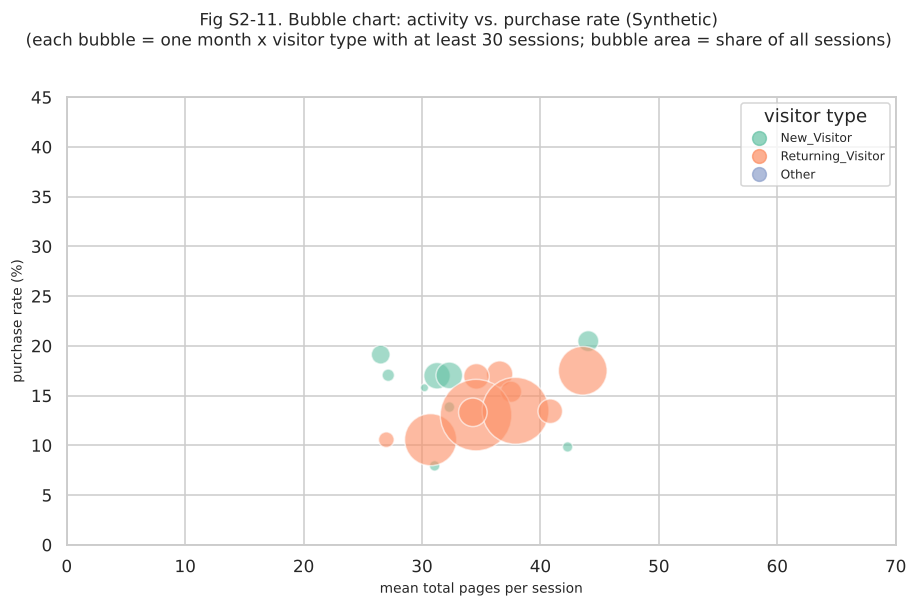

In [15]:
L.fig_bubble(df, S, "Fig S2-11. Bubble chart: activity vs. purchase rate (Synthetic)", FIG / "s2_11_bubble.png")
L.bubble_table(df).to_csv(RES / "bubble_table.csv", index=False)

**Interpretation (compared with Scenario 1).** The spread between the groups is compressed: purchase rates range from 7.9% to 20.5% (real 1.7% to 30.5%) and mean pages from 26.5 to 44.0 (real 12.0 to 53.1). The large groups no longer separate: returning visitors in May, November and December have purchase rates of 13.0%, 13.5% and 17.5% with 35 to 44 pages (real 9.2%, 24.8% and 9.7% with 30, 53 and 35 pages), and new visitors in November have 17.0% (real 30.5%). The strong November effect and the weak May and March conversion of the real data are not reproduced.

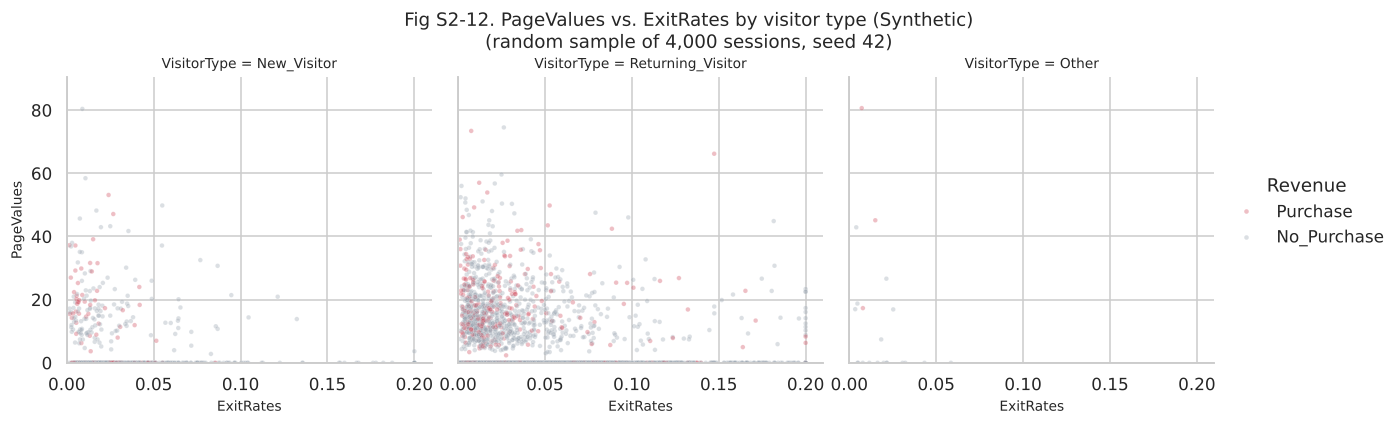

In [16]:
L.fig_facets(df, S, "Fig S2-12. PageValues vs. ExitRates by visitor type (Synthetic)", FIG / "s2_12_facets.png")

**Interpretation (compared with Scenario 1).** The negative relation between PageValues and ExitRates is kept in all three visitor types, but it is nearly the same everywhere: rho -0.20 for new visitors (real -0.22), -0.21 for returning visitors (real -0.32) and -0.13 for the 'Other' group (real -0.47, only 75 sessions). Purchasing sessions are less concentrated at high PageValues than in the real data.

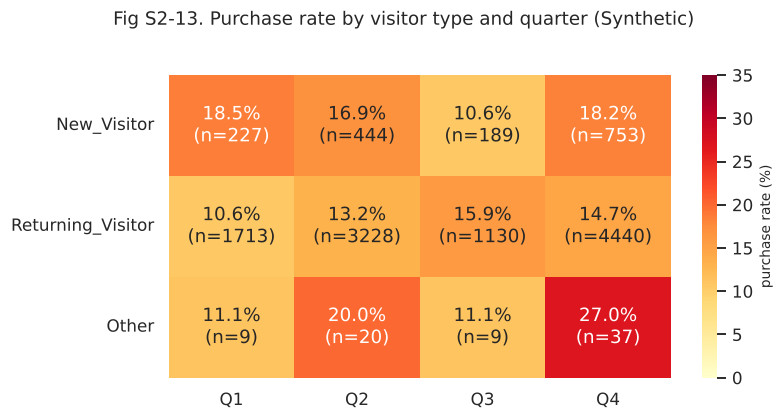

,pattern,group,value,n
0,ExitRates ~ PageValues within visitor type (Sp...,New_Visitor,-0.201,1613
1,ExitRates ~ PageValues within visitor type (Sp...,Other,-0.130,75
2,ExitRates ~ PageValues within visitor type (Sp...,Returning_Visitor,-0.206,10511
3,Total_Pages ~ PageValues within outcome (Spear...,No_Purchase,0.250,10468
4,Total_Pages ~ PageValues within outcome (Spear...,Purchase,0.224,1731
5,Purchase-rate gap New minus Returning visitors...,Q1,7.936,1949
6,Purchase-rate gap New minus Returning visitors...,Q2,3.664,3692
7,Purchase-rate gap New minus Returning visitors...,Q3,-5.347,1328
8,Purchase-rate gap New minus Returning visitors...,Q4,3.487,5230


In [17]:
L.fig_rate_matrix(df, S, "Fig S2-13. Purchase rate by visitor type and quarter (Synthetic)", FIG / "s2_13_rate_matrix.png")
mv = L.multivariate_evidence(df); mv.to_csv(RES / "multivariate_evidence.csv", index=False)
mv.round(3)

**Interpretation (compared with Scenario 1).** The interaction between visitor type and quarter is largely lost. Returning visitors rise only from 10.6% in Q1 to 15.9% in Q3 and fall to 14.7% in Q4 (real 8.8% to 19.7%). New visitors are between 10.6% and 18.5% in all quarters (real 15.5% in Q1 and 25.6% to 27.2% afterwards), and in Q3 they buy less than returning visitors (10.6% against 15.9%), although the intervals overlap (7.0% to 15.8% against 13.9% to 18.2%). The gap between new and returning visitors is +7.9, +3.7, -5.3 and +3.5 percentage points (real +6.7, +18.1, +10.1, +6.6). 'Other' visitors appear in all four quarters (9, 20, 9 and 37 sessions) while in the real data they occur only in Q2 (1 session) and Q4 (80 sessions), which shows that the association between visitor type and quarter was not kept. Within purchasing and non-purchasing sessions, Total_Pages and PageValues are positively correlated in both (+0.22 and +0.25), while in the real data they have opposite signs (-0.22 and +0.37).

## 5. Trends
The data has a `Month` label but no date column (no day and no year), so daily and yearly trends are not possible. Monthly trends and seasonality are analysed for the ten months present; the four quarters are used as a coarser view.

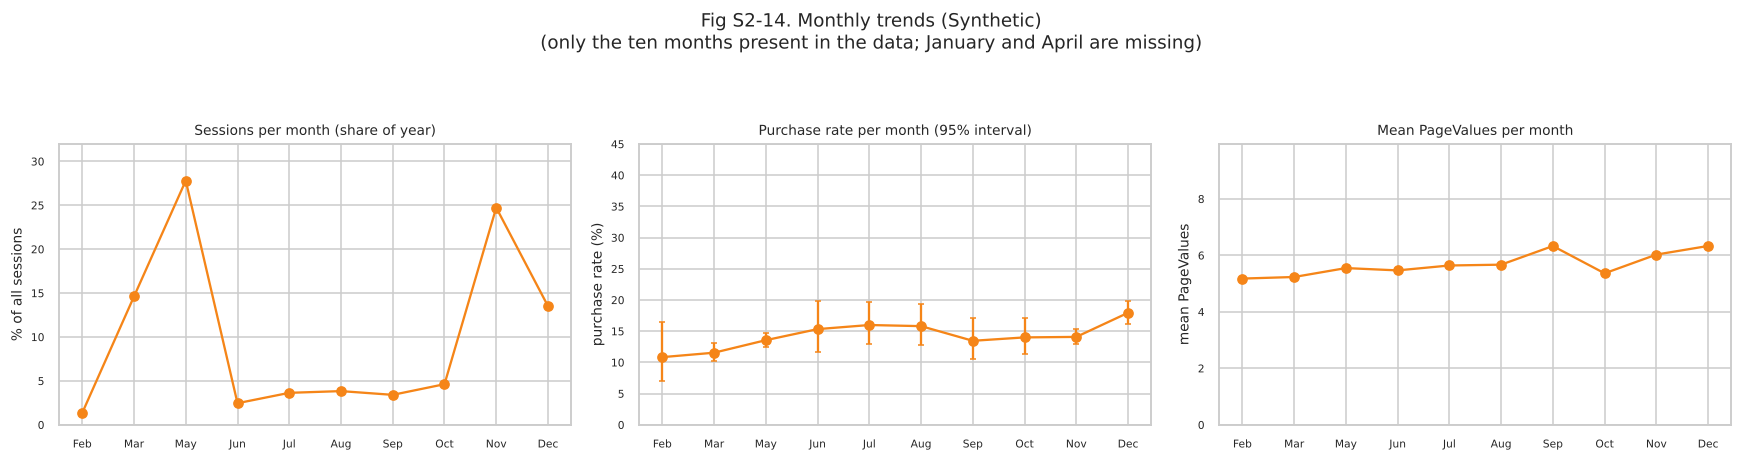

,n,purchases,rate,lo,hi,share,mean_PageValues
Month,,,,,,,
Feb,166,18,10.84,6.97,16.49,1.36,5.18
Mar,1783,206,11.55,10.15,13.12,14.62,5.23
May,3392,460,13.56,12.45,14.75,27.81,5.55
Jun,300,46,15.33,11.70,19.85,2.46,5.47
Jul,444,71,15.99,12.88,19.69,3.64,5.64
Aug,468,74,15.81,12.79,19.39,3.84,5.67
Sep,416,56,13.46,10.51,17.08,3.41,6.33
Oct,564,79,14.01,11.39,17.12,4.62,5.36
Nov,3017,425,14.09,12.89,15.37,24.73,6.03


In [18]:
L.fig_monthly(df, S, COLOR, "Fig S2-14. Monthly trends (Synthetic)", FIG / "s2_14_monthly_trend.png", LIM)
mt = L.monthly_table(df); mt.to_csv(RES / "monthly_table.csv")
mt.round(2)

**Interpretation (compared with Scenario 1).** The volume seasonality is reproduced: May has 27.8% of sessions (real 27.3%), November 24.7% (24.4%), March 14.6% and December 13.5%. The seasonality of conversion is not. The purchase rate stays between 10.8% (February) and 18.0% (December) with overlapping intervals, November is 14.1% (real 25.5%) and May is 13.6% (real 11.0%), and the real low in February (1.7%) becomes 10.8% (166 sessions, interval 7.0% to 16.5%). Mean PageValues is almost flat (5.2 to 6.3 against 0.9 to 8.7). Cramér's V of month against purchase is 0.053 against 0.176 in the real data. A user of the synthetic data would therefore see a busy May and November but would not find the November conversion peak.

## 6. Key findings

In [19]:
# numbers quoted in the findings, computed from the saved tables
ev = {}
ev["purchase_rate"] = 100 * (df.Revenue == "Purchase").mean()
ev["visitor_rate"] = L.rate_table(df, "VisitorType").set_index("VisitorType")[["n", "rate", "lo", "hi"]].round(2)
ev["quarter_rate"] = L.rate_table(df, "Quarter").set_index("Quarter")[["n", "rate", "lo", "hi"]].round(2)
ev["top_corr"] = (df[L.NUM].corr().where(np.triu(np.ones((len(L.NUM), len(L.NUM))), 1).astype(bool)).stack().rename("r").reset_index()
                  .assign(abs_r=lambda d: d.r.abs()).sort_values("abs_r", ascending=False).head(6).round(3))
for k, v in ev.items():
    print("==", k); print(v if not isinstance(v, float) else round(v, 2))

== purchase_rate
14.19
== visitor_rate
                       n   rate     lo     hi
VisitorType                                  
New_Visitor         1613  16.99  15.23  18.90
Other                 75  21.33  13.58  31.88
Returning_Visitor  10511  13.71  13.07  14.38
== quarter_rate
            n   rate     lo     hi
Quarter                           
Q1       1949  11.49  10.15  12.99
Q2       3692  13.71  12.63  14.85
Q3       1328  15.14  13.31  17.16
Q4       5230  15.30  14.35  16.30
== top_corr
                    level_0                  level_1      r  abs_r
60  ProductRelated_Duration           Total_Duration  0.998  0.998
51           ProductRelated              Total_Pages  0.998  0.998
25            Informational   Informational_Duration  0.733  0.733
0            Administrative  Administrative_Duration  0.699  0.699
85              Total_Pages           Total_Duration  0.675  0.675
52           ProductRelated           Total_Duration  0.671  0.671


### Summary of the key findings


**Finding 1: The synthetic data under-states the purchase rate and the strength of PageValues.**
*Observation:* 14.19% of synthetic sessions end in a purchase (95% interval 13.6% to 14.8%), below the real 15.64%; PageValues separates buyers from non-buyers much less. *Statistical evidence:* the rank-biserial effect of PageValues falls from 0.73 to 0.30, the median PageValues of buyers from 16.8 to 8.5, and the share of sessions with PageValues of 0 from 78% to 67%. Of sessions with PageValues above 20, 30% are purchases (real 73%). *Figures:* S2-05, S2-07, S2-10. *Significance:* models trained on this synthetic data would underestimate the value of PageValues as a signal.

**Finding 2: The seasonality of conversion is lost, although the seasonality of traffic is kept.**
*Observation:* traffic peaks in May (27.8%) and November (24.7%) as in the real data, but the monthly purchase rate stays between 10.8% and 18.0%. *Statistical evidence:* November converts at 14.1% against 25.5% in the real data; Cramér's V of month with purchase is 0.053 against 0.176; quarter 0.039 against 0.137 (Q1 11.5% to Q4 15.3% against 9.6% to 20.8%). *Figures:* S2-14, S2-08. *Significance:* the synthetic data cannot be used to study when customers buy, because the month and quarter effects are mostly gone.

**Finding 3: The visitor-type effect is weaker and the interaction with the quarter is lost.**
*Observation:* new visitors convert at 17.0% against 13.7% for returning visitors (real 24.9% against 14.1%). *Statistical evidence:* Cramér's V 0.036 against 0.103; the gap between new and returning visitors changes sign in Q3 (-5.3 percentage points, intervals overlapping), while in the real data it is positive in every quarter. 'Other' visitors appear in all four quarters, whereas in the real data they appear only in Q2 and Q4. *Figures:* S2-08, S2-13. *Significance:* relations between two categorical variables are the weakest part of the copula, and conclusions about combinations of categories should not be drawn from the synthetic data.

**Finding 4: Engagement relations keep their direction but are weaker.**
*Observation:* longer sessions still convert more (Long 17.8% against Short 11.1%), and product pages still rise with product time. *Statistical evidence:* Cramér's V of session length with purchase 0.078 against 0.185; Spearman of ProductRelated with its duration 0.74 against 0.88; rank-biserial of Total_Pages 0.14 against 0.32. *Figures:* S2-06, S2-08, S2-09. *Significance:* a user who only looks at the direction of a relationship will reach the same conclusion on both datasets; the size of the effect is understated by about a half.

**Finding 5: Bounce and exit rates are only loosely linked, and some relationships change sign.**
*Observation:* BounceRates and ExitRates correlate at 0.52 (Pearson) against 0.90 in the real data, and the cluster at the cap of 0.2 shrinks (BounceRates at 0.2: 0.2% against 4.7%). *Statistical evidence:* BounceRates with Avg_Time_Per_Page flips from -0.17 to +0.11 (Pearson); within purchasing sessions, Total_Pages with PageValues is +0.22 against -0.22 in the real data. *Figures:* S2-06, S2-09, S2-13. *Significance:* the strongest linear relation of the real data is the one the generator reproduces worst, so analyses that rely on it (for example collinearity checks) behave differently.

**Finding 6: The distribution shapes are reproduced in the centre but not in the tails.**
*Observation:* zero-inflation and right skew are kept, but the tails are lighter. *Statistical evidence:* skewness of PageValues 2.4 against 6.4, Informational 1.2 against 4.0, Informational_Duration 2.9 against 5.5; maxima of 125 against 362 (PageValues) and 6 against 24 (Informational). The synthetic Informational count is 2 for 20.1% of sessions (real 6.0%). *Figures:* S2-01, S2-02, S2-03. *Significance:* summary statistics based on the mean or standard deviation will be understated for these columns, and outlier analysis will find fewer extreme sessions.

## 7. Outputs
Figures: `figures/synthetic/scenario2/`; tables: `results/scenarios/scenario2_synthetic/`.